# nushell plot


In [1]:
from pathlib import Path
import json, io, zipfile, base64, math, sys, subprocess, importlib.util

ROOT = Path.cwd()
CSV = ROOT / 'PHL-PSA-SOF-2024-PUF 2/SOF PUF 2024.CSV'
assert CSV.exists(), 'Open this notebook from the base repository folder.'
if importlib.util.find_spec('shapely') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'shapely>=2.0'])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import colors, font_manager
from matplotlib.path import Path as MplPath
from matplotlib.patches import PathPatch, Polygon, Rectangle
from shapely.geometry import shape
from shapely.geometry.polygon import orient
from shapely.ops import unary_union
from IPython.display import display, Image

ASSETS = ROOT / '.plain_map_assets'
ASSETS.mkdir(exist_ok=True)
nb = json.loads((ROOT / 'nutshell_plain.ipynb').read_text(encoding='utf-8'))
with zipfile.ZipFile(io.BytesIO(base64.b64decode(nb['metadata']['map_assets']))) as archive:
    for member in archive.infolist():
        if not (ASSETS / member.filename).resolve().is_relative_to(ASSETS.resolve()):
            raise ValueError('Invalid asset path')
    archive.extractall(ASSETS)
for font_file in (ASSETS / 'assets/fonts').glob('*.ttf'):
    font_manager.fontManager.addfont(str(font_file))
geometry = json.loads((ASSETS / 'assets/geography/regions_2023.geojson').read_text())


## Text, colors and layout



In [2]:
TITLE = 'Overseas Work, Family Savings and Remittance Channels'
AUTHOR = 'CS 132 project team'
BANK_LEGEND = 'Bank remittance use'
SAVINGS_LEGEND = 'Family savings allocation'
HEIGHT_LABEL = '20% of remittances'
REGION_LEGEND = 'Labels: contract-worker share (%)\namong surveyed overseas Filipinos'
MEASURE_NOTE = 'Family savings = receiving-family allocation of remittances, not savings kept abroad. Regional estimates are survey weighted.'
DATA_CREDIT = 'Data: PSA Survey on Overseas Filipinos 2024 PUF'

BACKGROUND = '#1B181C'
TEXT = '#FFFFFF'
MUTED = '#C8C1CB'
MAP_COLORS = ['#4B2362', '#9E3E7F', '#DE6B61', '#EDB081']
MAP_SIDE = '#49304F'
OUTLINE = '#D9C8DD'
COLUMN_COLOR = '#FFB000'
COLUMN_SIDE = '#A56E12'
FONT = 'Roboto'
TITLE_SIZE = 51
LABEL_SIZE = 24
DEPTH = 15
TILT = 0.86
COLUMN_SCALE = 3.0
COLUMN_WIDTH = 9

# Region code: (visible name, label x, label y).
REGION_LABELS = {
    14: ('Cordillera', 415, 250),
    13: ('NCR', 430, 445),
    17: ('MIMAROPA', 370, 735),
    7: ('Central Visayas', 1300, 655),
    16: ('Caraga', 1340, 765),
    12: ('SOCCSKSARGEN', 1180, 920),
}


In [3]:
df = pd.read_csv(CSV, dtype=str, encoding='utf-8-sig')
for column in ['RREG', 'RSWGT', 'RQ10_REASON', 'RQ273P_SAVINGS', 'RQ26_MODE']:
    df[column] = pd.to_numeric(df[column].str.strip(), errors='coerce')
df['savings'] = df.RQ273P_SAVINGS.where(df.RQ273P_SAVINGS.between(0, 100))

def weighted_mean(values, weights):
    valid = values.notna() & weights.notna() & weights.gt(0)
    return float(np.average(values[valid].astype(float), weights=weights[valid]))

summary = {}
for region, group in df.groupby('RREG'):
    modes = group.loc[group.RQ26_MODE.notna()]
    summary[int(region)] = {
        'bank': 100 * weighted_mean(modes.RQ26_MODE.eq(1), modes.RSWGT),
        'savings': weighted_mean(group.savings, group.RSWGT),
        'contract': 100 * weighted_mean(group.RQ10_REASON.eq(1), group.RSWGT),
    }
assert len(summary) == 17


In [ ]:

geometries = {
    region: unary_union([
        shape(feature['geometry']) for feature in geometry['features']
        if feature['properties']['region'] == region
    ])
    for region in summary
}
geometries = {r: g if g.is_valid else g.buffer(0) for r, g in geometries.items()}

def polygons(geom):
    return [geom] if geom.geom_type == 'Polygon' else list(geom.geoms)

def mercator(point):
    lon, lat = point[:2]
    return np.array([math.radians(lon), -math.log(math.tan(math.pi / 4 + math.radians(lat) / 2))])

coords = np.array([
    mercator(p) for geom in geometries.values()
    for polygon in polygons(geom) for p in polygon.exterior.coords
])
low, high = coords.min(axis=0), coords.max(axis=0)
scale = min(950 / (high[0] - low[0]), 755 / (TILT * (high[1] - low[1])))
x_offset = 920 - scale * (high[0] - low[0]) / 2

def project(point):
    xy = mercator(point) - low
    return np.array([x_offset + xy[0] * scale, 185 + xy[1] * scale * TILT])

def polygon_path(geom, depth=0):
    vertices, codes = [], []
    for polygon in polygons(geom):
        polygon = orient(polygon, sign=1.0)
        for ring in [polygon.exterior, *polygon.interiors]:
            points = [project(p) + [0, depth] for p in ring.coords]
            vertices.extend(points)
            codes.extend([MplPath.MOVETO] + [MplPath.LINETO] * (len(points) - 2) + [MplPath.CLOSEPOLY])
    return MplPath(np.asarray(vertices), codes)

cmap = colors.LinearSegmentedColormap.from_list('bank_use', MAP_COLORS)
norm = colors.Normalize(vmin=20, vmax=65, clip=True)
plt.rcParams.update({'font.family': FONT, 'pdf.fonttype': 42, 'svg.fonttype': 'none'})
fig = plt.figure(figsize=(6.4, 3.6), dpi=300, facecolor=BACKGROUND)
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xlim(0, 1920)
ax.set_ylim(1080, 0)
ax.axis('off')

def label(x, y, value, size=24, weight='normal', ha='left', color=TEXT):
    return ax.text(x, y, value, fontsize=size * 72 / 300, color=color,
                   fontweight=weight, ha=ha, va='top', linespacing=1.1)

label(960, 65, TITLE, size=TITLE_SIZE, weight='bold', ha='center')


for depth in range(round(DEPTH), 0, -3):
    for geom in geometries.values():
        ax.add_patch(PathPatch(polygon_path(geom, depth), facecolor=MAP_SIDE,
                               edgecolor=MAP_SIDE, linewidth=0.15, zorder=1))
for region, geom in geometries.items():
    ax.add_patch(PathPatch(polygon_path(geom), facecolor=cmap(norm(summary[region]['bank'])),
                           edgecolor=OUTLINE, linewidth=0.25, zorder=2, gid=f'surface-region-{region}'))

centers = {r: project([g.centroid.x, g.centroid.y]) for r, g in geometries.items()}
for region in sorted(centers, key=lambda r: centers[r][1]):
    x, y = centers[region]
    height = summary[region]['savings'] * COLUMN_SCALE
    width, side = COLUMN_WIDTH, COLUMN_WIDTH * 0.55
    ax.add_patch(Polygon([[x-width/2, y], [x-width/2, y-height],
                          [x+width/2, y-height-side], [x+width/2, y-side]],
                         facecolor=COLUMN_COLOR, edgecolor='none', zorder=4, gid=f'column-front-region-{region}'))
    ax.add_patch(Polygon([[x+width/2, y-side], [x+width/2, y-height-side],
                          [x+width/2+side, y-height], [x+width/2+side, y]],
                         facecolor=COLUMN_SIDE, edgecolor='none', zorder=4, gid=f'column-side-region-{region}'))

# Edit labels and their positions in REGION_LABELS
for region, (name, tx, ty) in REGION_LABELS.items():
    x, y = centers[region]
    heading = f"{name} ({summary[region]['contract']:.1f}%)"
    end_x = min(max(x, tx), tx + len(heading) * LABEL_SIZE * 0.53)
    end_y = ty - 8 if ty > y else ty + LABEL_SIZE + 7
    ax.plot([x, end_x], [y, end_y], color=MUTED, linewidth=0.3, zorder=5)
    label(tx, ty, heading, size=LABEL_SIZE).set_gid(f'label-region-{region}')

# Color legend
label(1450, 225, BANK_LEGEND, size=24, weight='bold')
ax.imshow(np.linspace(20, 65, 400).reshape(1, -1),
          extent=(1450, 1800, 285, 263), cmap=cmap, norm=norm, aspect='auto', zorder=1)
for x, value in [(1450, '20%'), (1600, '40%'), (1760, '65%')]:
    label(x, 300, value, size=21, color=MUTED)

label(1450, 390, SAVINGS_LEGEND, size=24, weight='bold')
example_height = 20 * COLUMN_SCALE
ax.add_patch(Rectangle((1450, 520-example_height), COLUMN_WIDTH, example_height,
                       facecolor=COLUMN_COLOR, edgecolor='none'))
label(1480, 485, HEIGHT_LABEL, size=22)
label(1450, 555, REGION_LEGEND, size=21, color=MUTED)

label(80, 986, MEASURE_NOTE, size=19, color=MUTED)
label(1840, 1026, DATA_CREDIT, size=18, color=MUTED, ha='right')
label(1840, 1050, f'Chart: {AUTHOR} | Boundaries: J. Faeldon (2023 vintage, MIT)',
      size=18, color=MUTED, ha='right')

plt.close(fig)


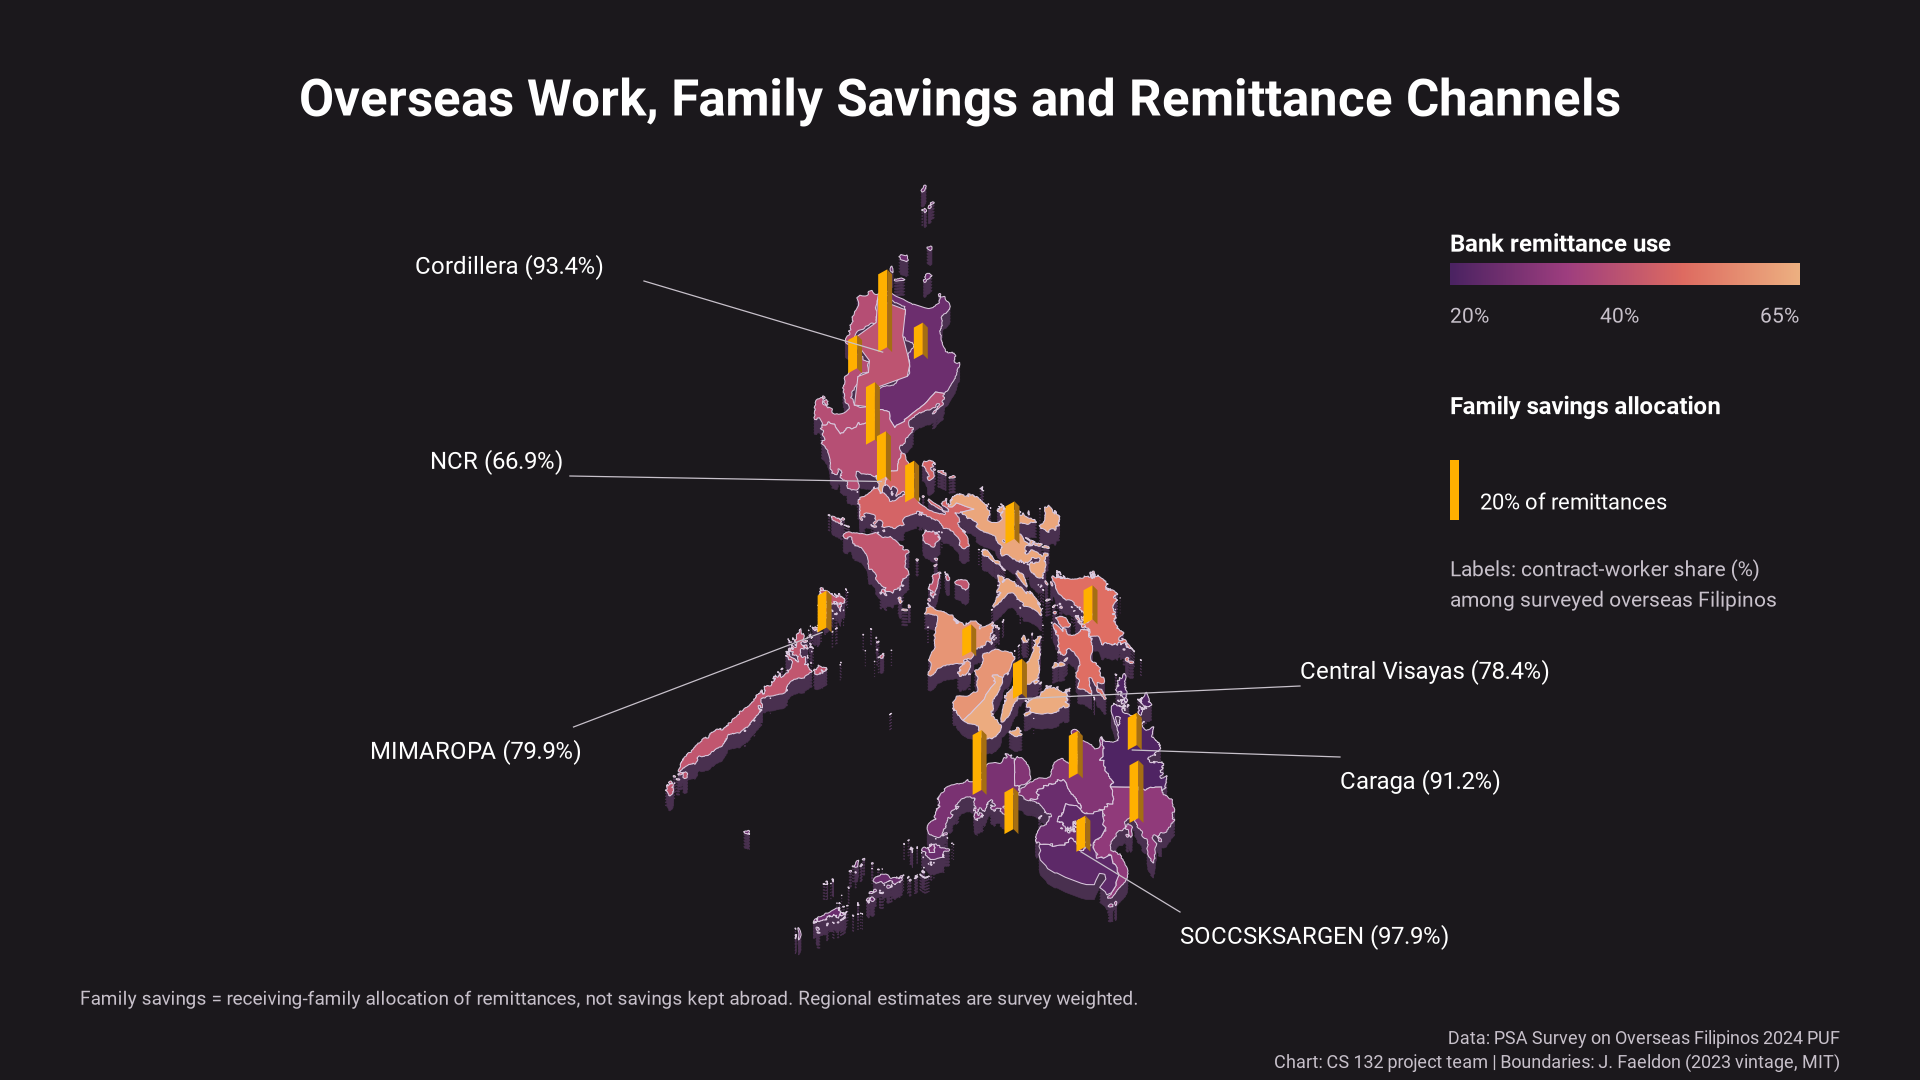

In [5]:
OUTPUT = ROOT / 'nutshell_plain_output'
OUTPUT.mkdir(exist_ok=True)
fig.savefig(OUTPUT / 'nutshell_plain.png', dpi=300, facecolor=BACKGROUND)
fig.savefig(OUTPUT / 'nutshell_plain.pdf', dpi=300, facecolor=BACKGROUND)
fig.savefig(OUTPUT / 'nutshell_plain.svg', facecolor=BACKGROUND)
plt.close(fig)
display(Image(filename=str(OUTPUT / 'nutshell_plain.png')))


## HTML Map to use for website

In [ ]:
"""Run this cell after the plot and static export cells."""
import html as html_lib
import re

REGION_NAMES = {
    1: 'Ilocos', 2: 'Cagayan Valley', 3: 'Central Luzon', 4: 'CALABARZON',
    5: 'Bicol', 6: 'Western Visayas', 7: 'Central Visayas', 8: 'Eastern Visayas',
    9: 'Zamboanga Peninsula', 10: 'Northern Mindanao', 11: 'Davao',
    12: 'SOCCSKSARGEN', 13: 'NCR', 14: 'Cordillera', 16: 'Caraga',
    17: 'MIMAROPA', 19: 'BARMM',
}

svg_text = (OUTPUT / 'nutshell_plain.svg').read_text(encoding='utf-8')
svg_text = svg_text[svg_text.index('<svg'):]
svg_text = svg_text.replace('<svg ', '<svg aria-label="Interactive regional map of the Philippines" ', 1)

font_css = []
for weight, filename in [(400, 'Regular'), (500, 'Medium'), (700, 'Bold')]:
    encoded = base64.b64encode((ASSETS / f'assets/fonts/Roboto-{filename}.ttf').read_bytes()).decode('ascii')
    font_css.append(
        f"@font-face {{font-family:'Roboto';font-weight:{weight};font-style:normal;"
        f"src:url(data:font/ttf;base64,{encoded}) format('truetype');}}"
    )

records = []
for region, estimates in summary.items():
    group = df.loc[df.RREG.eq(region)]
    records.append({
        'region': region, 'name': REGION_NAMES[region], **estimates,
        'n_contract': len(group),
        'n_savings': int(group.savings.notna().sum()),
        'n_bank': int(group.RQ26_MODE.notna().sum()),
    })
assert len(records) == 17
payload = json.dumps(records, allow_nan=False).replace('<', '\\u003c')
licenses = json.dumps({
    'Roboto': (ASSETS / 'assets/fonts/ROBOTO_LICENSE.txt').read_text(encoding='utf-8'),
    'Map boundaries': (ASSETS / 'assets/geography/LICENSE.txt').read_text(encoding='utf-8'),
    'Boundary attribution': (ASSETS / 'assets/geography/ATTRIBUTION.md').read_text(encoding='utf-8'),
}).replace('<', '\\u003c')

template = r'''<!doctype html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>__TITLE__</title>
<style>
__FONTS__
:root { --map-bg:__BG__; --map-text:__TEXT__; --map-muted:__MUTED__; --map-selected:__SELECTED__; }
* { box-sizing:border-box; }
body { margin:0; background:var(--map-bg); color:var(--map-text); font-family:Roboto,Arial,sans-serif; }
main { max-width:1100px; margin:auto; padding:14px 18px 18px; }
.controls { display:flex; align-items:center; gap:10px 16px; flex-wrap:wrap; }
.controls label { font-size:14px; font-weight:500; }
select { max-width:100%; min-height:44px; font:inherit; font-size:16px; color:var(--map-text); background:var(--map-bg); border:1px solid var(--map-muted); border-radius:4px; padding:8px 32px 8px 10px; }
.hint { color:var(--map-muted); font-size:13px; }
.map-stage > svg { display:block; width:100%; height:auto; }
.map-stage [data-region] { cursor:pointer; }
.map-stage [data-kind="surface"].is-selected path { stroke:var(--map-selected) !important; stroke-width:1.3 !important; vector-effect:non-scaling-stroke; }
.map-stage [data-region]:focus { outline:none; }
.map-stage [data-region]:focus-visible path { stroke:var(--map-text) !important; stroke-width:2 !important; vector-effect:non-scaling-stroke; }
.details { border-top:1px solid var(--map-muted); padding-top:14px; }
.details h2 { margin:0 0 12px; font-size:20px; font-weight:500; }
.metrics { display:grid; grid-template-columns:repeat(3,minmax(0,1fr)); gap:14px 24px; }
.metric-label { font-size:13px; color:var(--map-muted); }
.metric-value { display:block; margin:5px 0; font-size:25px; font-weight:500; font-variant-numeric:tabular-nums; }
.metric-sample { font-size:12px; color:var(--map-muted); }
.note { margin:14px 0 0; color:var(--map-muted); font-size:12px; line-height:1.5; }
.map-stage > svg:focus { outline:none; }
@media(max-width:600px) { main{padding:12px;} .metrics{grid-template-columns:1fr;gap:13px;} .metric-value{display:inline;margin:0 10px 0 0;font-size:23px;} .metric-label{display:block;margin-bottom:4px;} .metric-sample{display:inline;} .hint{flex-basis:100%;} }
</style>
</head>
<body>
<main>
 <div class="controls">
  <label for="region-select">Region</label>
  <select id="region-select" aria-label="Inspect a Philippine region"></select>
  <span class="hint">Tap/click the land or a gold column. Hover to preview.</span>
 </div>
 <div class="map-stage" id="map-stage">__SVG__</div>
 <section class="details" aria-live="polite" aria-atomic="true">
  <h2 id="region-name"></h2>
  <div class="metrics">
   <div><span class="metric-label">Contract-worker share</span><strong class="metric-value" id="contract-value"></strong><span class="metric-sample" id="contract-sample"></span></div>
   <div><span class="metric-label">Family savings allocation</span><strong class="metric-value" id="savings-value"></strong><span class="metric-sample" id="savings-sample"></span></div>
   <div><span class="metric-label">Bank remittance use</span><strong class="metric-value" id="bank-value"></strong><span class="metric-sample" id="bank-sample"></span></div>
  </div>
 </section>
 <p class="note">Survey-weighted regional estimates; samples differ by measure. Savings means the receiving family's share of remittances allocated to savings, not savings kept abroad. Base depth is decorative.</p>
</main>
<script type="application/json" id="regional-data">__DATA__</script>
<script type="application/json" id="asset-licenses">__LICENSES__</script>
<script>
(() => {
 const rows=JSON.parse(document.getElementById('regional-data').textContent);
 const data=new Map(rows.map(row=>[row.region,row]));
 const stage=document.getElementById('map-stage');
 const select=document.getElementById('region-select');
 let selected=13;
 const percent=new Intl.NumberFormat('en',{minimumFractionDigits:1,maximumFractionDigits:1});
 const count=new Intl.NumberFormat('en');
 const metric=(id,text)=>{document.getElementById(id).textContent=text;};
 function describe(region) {
  const row=data.get(region);
  metric('region-name',row.name);
  for(const field of ['contract','savings','bank']) {
   metric(field+'-value',percent.format(row[field])+'%');
   metric(field+'-sample','n = '+count.format(row['n_'+field])+' records');
  }
 }
 function activate(region) {
  if(!data.has(region)) return;
  selected=region; select.value=String(region);
  for(const mark of stage.querySelectorAll('[data-region]')) {
   const active=Number(mark.dataset.region)===region;
   mark.classList.toggle('is-selected',active);
   mark.setAttribute('aria-pressed',String(active));
  }
  describe(region);
 }
 for(const row of [...rows].sort((a,b)=>a.name.localeCompare(b.name))) {
  const option=document.createElement('option');
  option.value=String(row.region); option.textContent=row.name; select.appendChild(option);
 }
 for(const mark of stage.querySelectorAll('[id]')) {
  const match=/^(surface|column-front|column-side|label)-region-(\d+)$/.exec(mark.id);
  if(!match) continue;
  const region=Number(match[2]),row=data.get(region);
  if(!row) continue;
  mark.dataset.region=String(region); mark.dataset.kind=match[1];
  mark.setAttribute('role','button');
  mark.setAttribute('aria-label',row.name+'; contract workers '+percent.format(row.contract)+'%; family savings '+percent.format(row.savings)+'%; bank use '+percent.format(row.bank)+'%');
  // One tab stop per region. Column faces and labels remain pointer/touch targets.
  if(match[1]==='surface') mark.setAttribute('tabindex','0');
  mark.addEventListener('click',()=>activate(region));
  mark.addEventListener('keydown',event=>{
   if(event.key==='Enter'||event.key===' ') {event.preventDefault();activate(region);}
  });
  mark.addEventListener('pointerenter',event=>{if(event.pointerType==='mouse') describe(region);});
  mark.addEventListener('pointerleave',()=>describe(selected));
 }
 select.addEventListener('change',()=>activate(Number(select.value)));
 activate(selected);
})();
</script>
</body>
</html>'''

interactive_html = template
for token, value in {
    '__TITLE__': html_lib.escape(TITLE), '__FONTS__': '\n'.join(font_css),
    '__BG__': colors.to_hex(BACKGROUND), '__TEXT__': colors.to_hex(TEXT),
    '__MUTED__': colors.to_hex(MUTED), '__SELECTED__': colors.to_hex(COLUMN_COLOR),
    '__SVG__': svg_text, '__DATA__': payload, '__LICENSES__': licenses,
}.items():
    interactive_html = interactive_html.replace(token, value)

interactive_file = OUTPUT / 'nutshell_interactive.html'
interactive_file.write_text(interactive_html, encoding='utf-8')

from IPython.display import HTML
display(HTML(
    '<iframe title="Interactive Philippine map" sandbox="allow-scripts" '
    'style="width:100%;height:850px;border:0;" srcdoc="'
    + html_lib.escape(interactive_html, quote=True) + '"></iframe>'
))
